<a href="https://colab.research.google.com/github/manojss14/ML2_MANOJSS_4NI22CI034/blob/main/ML2_exp02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-learn libraries
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

display(df.head())

Saving student_performance.csv to student_performance.csv
Dataset loaded successfully!


,Student_ID,Name,Age,Gender,Math_Score,Science_Score,Attendance
0,1,Rahul,20,Male,85.0,90.0,95.0
1,2,Priya,21,Female,92.0,88.0,98.0
2,3,Amit,19,Male,76.0,80.0,85.0
3,4,Sneha,20,Female,89.0,94.0,92.0
4,5,Karan,22,Male,65.0,70.0,78.0


In [3]:
# Remove duplicate records
df = df.drop_duplicates()

# Handle missing numerical values
df['Math_Score'] = df['Math_Score'].fillna(
    df['Math_Score'].median()
)

df['Science_Score'] = df['Science_Score'].fillna(
    df['Science_Score'].median()
)

# Calculate average marks
df['Average_Score'] = (
    df['Math_Score'] + df['Science_Score']
) / 2

# Create target variable
df['Result'] = np.where(
    df['Average_Score'] >= 40,
    1,
    0
)

print("Data preprocessing completed!")

display(df.head())

Data preprocessing completed!


,Student_ID,Name,Age,Gender,Math_Score,Science_Score,Attendance,Average_Score,Result
0,1,Rahul,20,Male,85.0,90.0,95.0,87.5,1
1,2,Priya,21,Female,92.0,88.0,98.0,90.0,1
2,3,Amit,19,Male,76.0,80.0,85.0,78.0,1
3,4,Sneha,20,Female,89.0,94.0,92.0,91.5,1
4,5,Karan,22,Male,65.0,70.0,78.0,67.5,1


In [4]:
# Input features
X = df[['Math_Score', 'Science_Score']]

# Target variable
y = df['Result']

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

Input Features:


,Math_Score,Science_Score
0,85.0,90.0
1,92.0,88.0
2,76.0,80.0
3,89.0,94.0
4,65.0,70.0



Target Variable:


,Result
0,1
1,1
2,1
3,1
4,1


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed!")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training and Testing Split Completed!
Training Data: (16, 2)
Testing Data: (4, 2)


In [6]:
# Create classifier
model = DecisionTreeClassifier(
    random_state=42,
    max_depth=3
)

# Train model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [7]:
# Predict test data
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[1 1 1 1]

Predicted Values:
[1 1 1 1]


In [8]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# Display results
print("MODEL EVALUATION RESULTS")

print("----------------------------")

print("Accuracy :", accuracy)

print("Precision:", precision)

print("Recall   :", recall)

print("F1 Score :", f1)

MODEL EVALUATION RESULTS
----------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


In [9]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Fail', 'Pass'],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         0
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         4
   macro avg       0.50      0.50      0.50         4
weighted avg       1.00      1.00      1.00         4



Confusion Matrix:
[[0 0]
 [0 4]]


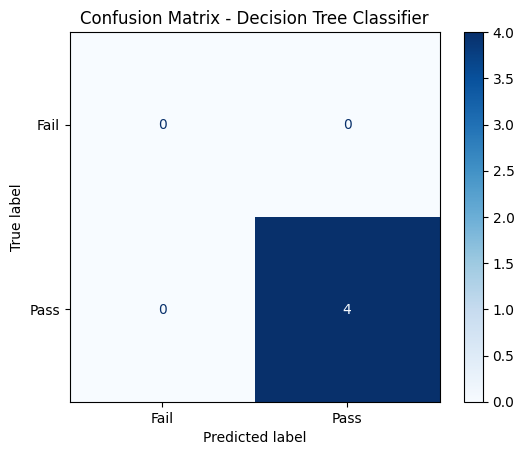

In [10]:
# Calculate confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

disp.plot(cmap='Blues', values_format='d')

plt.title("Confusion Matrix - Decision Tree Classifier")

plt.show()

In [11]:
# New student marks
new_student = pd.DataFrame({
    'Math_Score': [85],
    'Science_Score': [90]
})

# Predict
prediction = model.predict(new_student)

if prediction[0] == 1:
    print("Student Result: PASS")
else:
    print("Student Result: FAIL")

Student Result: PASS


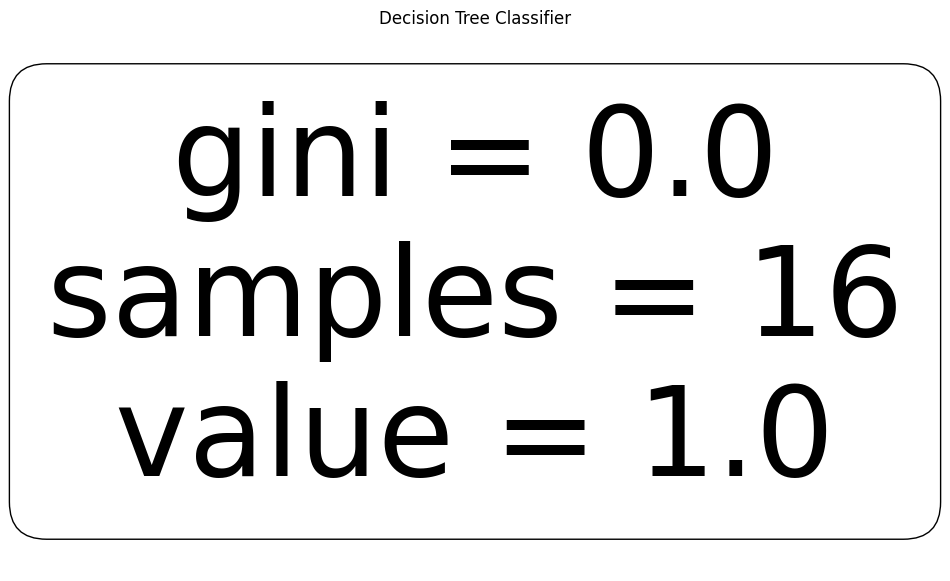

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 7))

plot_tree(
    model,
    feature_names=['Math_Score', 'Science_Score'],
    class_names=['Fail', 'Pass'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier")

plt.show()